# StyleBot Preparación común de datos

    Este notebook prepara la parte del líder para la primera entrega: cargar Fashion-MNIST, separar datos, comprobar categorías y generar evidencia para el equipo. No entrena clasificadores.

    **Responsable:** Krysto Alberto Adan Jauregui Zuñiga.

    **Cómo usarlo:** abre el archivo en Google Colab y ejecuta las celdas de arriba hacia abajo. Para este trabajo basta el entorno normal de CPU. Conserva una copia en tu Google Drive. La primera ejecución necesita conexión a Internet para descargar el dataset.

    **Estado del archivo:** es una plantilla lista para ejecutar, con salidas vacías. Las comprobaciones que aparecen al ejecutarlo corresponden a tu propia sesión. Lee y explica el código; cita las fuentes y reconoce la asistencia utilizada según las reglas de tu curso.

## 1 Carga común para todo el equipo

    Esta celda define las categorías y las funciones. Todos deben conservarla igual. `X` contiene imágenes y `y` las categorías correctas.

    La prueba oficial tiene 10,000 imágenes. De las otras 60,000 apartamos 20 % para validación: quedan 48,000 para entrenamiento y 12,000 para validación. `stratify` conserva la proporción de las categorías y la semilla 42 fija la división. Los píxeles ya quedan normalizados entre 0 y 1; no vuelvas a dividirlos entre 255.

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split

SEMILLA = 42
CATEGORIAS = [
    "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
    "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"
]

def preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba):
    """Divide los 60,000 ejemplos originales y conserva la prueba oficial."""
    assert X_base.shape == (60000, 28, 28)
    assert y_base.shape == (60000,)
    assert X_prueba.shape == (10000, 28, 28)
    assert y_prueba.shape == (10000,)
    assert X_base.dtype == np.uint8 and X_prueba.dtype == np.uint8

    # Los índices permiten identificar exactamente las imágenes de cada parte.
    indices = np.arange(len(y_base), dtype=np.int64)
    idx_train, idx_val = train_test_split(
        indices, test_size=0.20, random_state=SEMILLA, stratify=y_base
    )

    # Normalizar una sola vez: uint8 de 0 a 255 -> float32 de 0 a 1.
    datos = {
        "X_train": X_base[idx_train].astype(np.float32) / np.float32(255.0),
        "y_train": y_base[idx_train].copy(),
        "X_val": X_base[idx_val].astype(np.float32) / np.float32(255.0),
        "y_val": y_base[idx_val].copy(),
        "X_test": X_prueba.astype(np.float32) / np.float32(255.0),
        "y_test": y_prueba.copy(),
        "idx_train": idx_train,
        "idx_val": idx_val,
        # Estos índices pertenecen al archivo de prueba, no al de entrenamiento.
        "idx_test": np.arange(len(y_prueba), dtype=np.int64),
    }
    return datos

def cargar_datos_stylebot():
    """Descarga Fashion-MNIST automáticamente mediante TensorFlow/Keras."""
    from tensorflow.keras.datasets import fashion_mnist
    (X_base, y_base), (X_prueba, y_prueba) = fashion_mnist.load_data()
    return preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba)


## 2 Descargar y preparar Fashion MNIST

    Ejecuta la siguiente celda. `fashion_mnist.load_data()` descarga automáticamente los archivos oficiales a través de TensorFlow/Keras.

    Esperamos estas formas: entrenamiento `(48000, 28, 28)`, validación `(12000, 28, 28)` y prueba `(10000, 28, 28)`. La descarga puede tardar la primera vez.

In [2]:
datos = cargar_datos_stylebot()
X_train, y_train = datos["X_train"], datos["y_train"]
X_val, y_val = datos["X_val"], datos["y_val"]
X_test, y_test = datos["X_test"], datos["y_test"]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:   ", X_val.shape, y_val.shape)
print("Prueba:       ", X_test.shape, y_test.shape)
print("Píxeles:", X_train.dtype, "de", X_train.min(), "a", X_train.max())


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (48000, 28, 28) (48000,)
Validación:    (12000, 28, 28) (12000,)
Prueba:        (10000, 28, 28) (10000,)
Píxeles: float32 de 0.0 a 1.0


## 3 Comprobar la división y los valores

    Las instrucciones `assert` detienen la ejecución si algo no coincide con lo esperado. Conservamos los índices de entrenamiento y validación para verificar que no se mezclaron. Los índices de prueba pertenecen a un archivo diferente.

    Revisamos forma, cantidad, rango, valores no finitos y categorías. Esto no equivale a una inspección exhaustiva de daños visuales ni a una búsqueda de duplicados de contenido.

In [3]:
# Esta comprobación NO evalúa modelos: verifica la preparación de datos.
assert len(np.intersect1d(datos["idx_train"], datos["idx_val"])) == 0
assert len(np.union1d(datos["idx_train"], datos["idx_val"])) == 60000

comprobaciones = []
for nombre, X, y, cantidad in [
    ("entrenamiento", X_train, y_train, 48000),
    ("validacion", X_val, y_val, 12000),
    ("prueba", X_test, y_test, 10000),
]:
    assert X.shape == (cantidad, 28, 28)
    assert y.shape == (cantidad,)
    assert X.dtype == np.float32
    assert np.isfinite(X).all()
    assert X.min() >= 0.0 and X.max() <= 1.0
    assert np.isin(y, np.arange(10)).all()
    conteos = np.bincount(y, minlength=10)
    assert np.all(conteos == cantidad // 10)
    comprobaciones.append({
        "conjunto": nombre, "imagenes": cantidad,
        "forma_imagen": "28x28", "tipo_pixeles": str(X.dtype),
        "minimo": float(X.min()), "maximo": float(X.max()),
        "valores_no_finitos": int((~np.isfinite(X)).sum()),
        "etiquetas_invalidas": int((~np.isin(y, np.arange(10))).sum()),
    })
    print(nombre, "OK:", cantidad, "imágenes;", conteos.tolist(), "por categoría")

print("OK: entrenamiento y validación no comparten índices.")
print("La prueba conserva las 10,000 imágenes del archivo oficial de prueba.")
print("Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.")


entrenamiento OK: 48000 imágenes; [4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800] por categoría
validacion OK: 12000 imágenes; [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200] por categoría
prueba OK: 10000 imágenes; [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000] por categoría
OK: entrenamiento y validación no comparten índices.
La prueba conserva las 10,000 imágenes del archivo oficial de prueba.
Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.


## 4 Ver las categorías y sus cantidades

    Los números tienen el mismo significado para todos los integrantes. Camiseta es 0 y camisa es 6; no deben intercambiarse. Con esta división esperamos 4,800 imágenes de entrenamiento, 1,200 de validación y 1,000 de prueba por categoría.

In [4]:
print("ID | Categoría | Entrenamiento | Validación | Prueba")
conteo_clases = []
for identificador, categoria in enumerate(CATEGORIAS):
    fila = {
        "id": identificador, "categoria": categoria,
        "entrenamiento": int(np.sum(y_train == identificador)),
        "validacion": int(np.sum(y_val == identificador)),
        "prueba": int(np.sum(y_test == identificador)),
    }
    conteo_clases.append(fila)
    print(f"{identificador:2} | {categoria:9} | {fila['entrenamiento']:5} | {fila['validacion']:5} | {fila['prueba']:5}")


ID | Categoría | Entrenamiento | Validación | Prueba
 0 | Camiseta  |  4800 |  1200 |  1000
 1 | Pantalón  |  4800 |  1200 |  1000
 2 | Suéter    |  4800 |  1200 |  1000
 3 | Vestido   |  4800 |  1200 |  1000
 4 | Abrigo    |  4800 |  1200 |  1000
 5 | Sandalia  |  4800 |  1200 |  1000
 6 | Camisa    |  4800 |  1200 |  1000
 7 | Tenis     |  4800 |  1200 |  1000
 8 | Bolso     |  4800 |  1200 |  1000
 9 | Botín     |  4800 |  1200 |  1000


## 5 Guardar las tablas y las reglas del equipo

    Se guardan categorías, conteos, comprobaciones, índices y un protocolo con la semilla, las versiones y las huellas de la división. El archivo de índices es pequeño: no contiene las imágenes.

    Si dos integrantes usan diferentes versiones, comparen las huellas en `protocolo_datos.json`. Si no coinciden, acuerden una misma versión o reutilicen los índices del líder antes de comparar modelos.

In [5]:
from pathlib import Path
import csv
import hashlib
import importlib.metadata
import json
import zipfile

# Todos los resultados se escriben en esta carpeta, dentro de la sesión actual.
CARPETA_SALIDA = Path("StyleBot_datos_generados")
for subcarpeta in ["datos", "resultados/tablas", "resultados/graficas"]:
    (CARPETA_SALIDA / subcarpeta).mkdir(parents=True, exist_ok=True)

def guardar_csv(ruta, filas):
    with ruta.open("w", newline="", encoding="utf-8-sig") as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=list(filas[0].keys()))
        escritor.writeheader()
        escritor.writerows(filas)

guardar_csv(CARPETA_SALIDA / "datos/categorias.csv", [
    {"id": i, "categoria": nombre} for i, nombre in enumerate(CATEGORIAS)
])
guardar_csv(CARPETA_SALIDA / "resultados/tablas/conteo_clases.csv", conteo_clases)
guardar_csv(CARPETA_SALIDA / "resultados/tablas/verificacion_datos.csv", comprobaciones)

np.savez_compressed(
    CARPETA_SALIDA / "datos/particiones_semilla42.npz",
    idx_train=datos["idx_train"], idx_val=datos["idx_val"], idx_test=datos["idx_test"]
)

versiones = {}
for paquete in ["numpy", "scikit-learn", "matplotlib", "tensorflow"]:
    try:
        versiones[paquete] = importlib.metadata.version(paquete)
    except importlib.metadata.PackageNotFoundError:
        versiones[paquete] = "no detectado en este entorno"

huellas_indices = {
    nombre: hashlib.sha256(datos[nombre].astype("<i8").tobytes()).hexdigest()
    for nombre in ["idx_train", "idx_val", "idx_test"]
}
protocolo = {
    "dataset": "Fashion-MNIST", "semilla": SEMILLA,
    "entrenamiento": 48000, "validacion": 12000, "prueba": 10000,
    "origen_train_val": "60,000 imágenes oficiales de entrenamiento",
    "origen_test": "10,000 imágenes oficiales de prueba, conservadas",
    "separacion": "train_test_split, test_size=0.20, stratify=y_base",
    "forma_imagen": [28, 28], "normalizacion": "float32 / 255.0, una sola vez",
    "categorias": {str(i): nombre for i, nombre in enumerate(CATEGORIAS)},
    "sha256_indices": huellas_indices, "versiones": versiones,
}
(CARPETA_SALIDA / "datos/protocolo_datos.json").write_text(
    json.dumps(protocolo, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Resultados guardados en:", CARPETA_SALIDA.resolve())
print("Huella de la división de entrenamiento:", huellas_indices["idx_train"])


Resultados guardados en: /content/StyleBot_datos_generados
Huella de la división de entrenamiento: 1c0cffec1476c830767b282ef3e3354d14cb1e3e2ecb436f13ee8537f0de19c9


## 6 Mostrar ejemplos y distribución

    Estas figuras sirven para revisar que las categorías y sus imágenes tengan sentido. La selección de ejemplos utiliza únicamente entrenamiento.

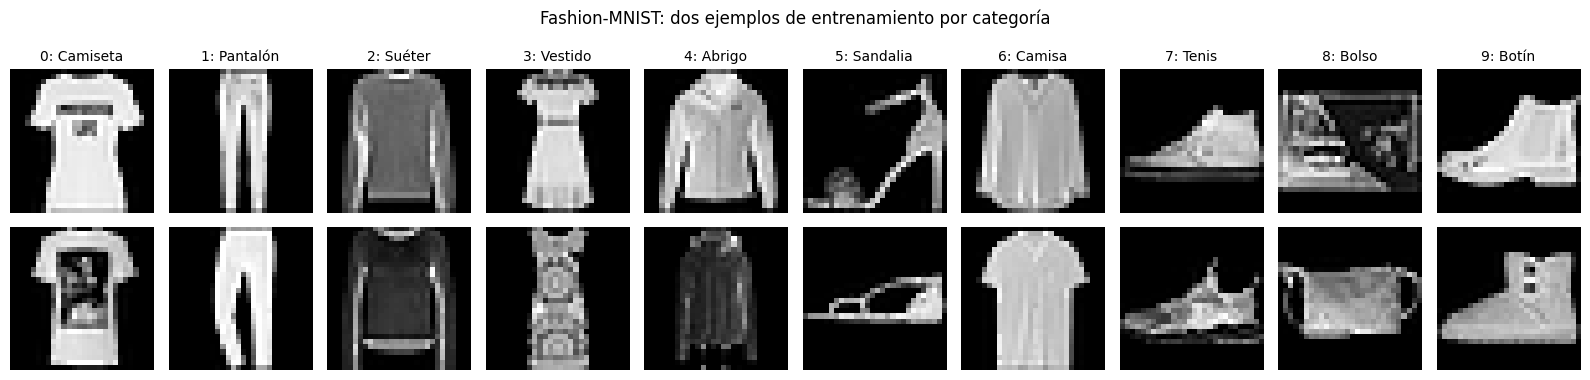

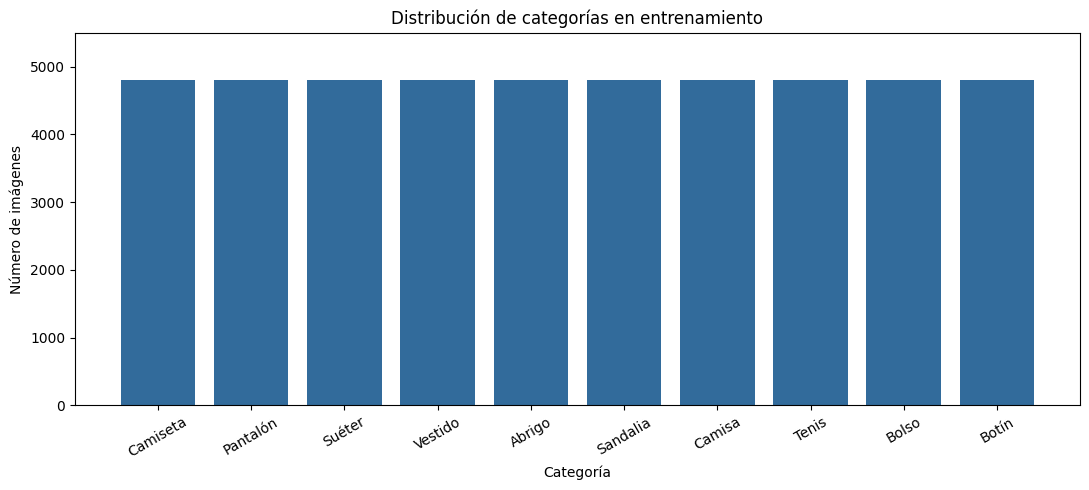

In [6]:
import matplotlib.pyplot as plt

# Solo usamos entrenamiento para elegir los ejemplos exploratorios.
fig, ejes = plt.subplots(2, 10, figsize=(16, 4))
for categoria_id, nombre in enumerate(CATEGORIAS):
    ejemplos = np.flatnonzero(y_train == categoria_id)[:2]
    for fila, indice in enumerate(ejemplos):
        ejes[fila, categoria_id].imshow(X_train[indice], cmap="gray", vmin=0, vmax=1)
        ejes[fila, categoria_id].axis("off")
        if fila == 0:
            ejes[fila, categoria_id].set_title(f"{categoria_id}: {nombre}", fontsize=10)
fig.suptitle("Fashion-MNIST: dos ejemplos de entrenamiento por categoría")
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "resultados/graficas/ejemplos_prendas.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(CATEGORIAS, np.bincount(y_train, minlength=10), color="#326b9b")
ax.set_title("Distribución de categorías en entrenamiento")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de imágenes")
ax.tick_params(axis="x", rotation=30)
ax.set_ylim(0, 5500)
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "resultados/graficas/distribucion_entrenamiento.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


## 7 Descargar los resultados para el equipo

    La siguiente celda descarga un ZIP con las tablas, figuras y protocolo. Guárdalo en tu computadora y extráelo antes de subir los archivos a GitHub.

    Además, descarga este notebook desde Archivo y Descargar como `.ipynb` después de ejecutarlo. Ese archivo conservará las salidas de tu sesión. El ZIP de resultados no incluye automáticamente el notebook.

In [7]:
ruta_zip = Path("StyleBot_datos_generados.zip")
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as comprimido:
    for ruta in sorted(CARPETA_SALIDA.rglob("*")):
        if ruta.is_file():
            comprimido.write(ruta, ruta.relative_to(CARPETA_SALIDA))
print("Archivo preparado:", ruta_zip.resolve())

# En Colab, esta línea ofrece el ZIP para descargar a tu computadora.
try:
    from google.colab import files
except ImportError:
    print("Fuera de Colab: abre el ZIP en la ruta indicada arriba.")
else:
    files.download(str(ruta_zip))


Archivo preparado: /content/StyleBot_datos_generados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8 Revisar y entregar

    - Comprueba que no haya errores y que las categorías coincidan con las imágenes.
    - Escribe tu nombre y una explicación con tus propias palabras.
    - Sube el notebook ejecutado, `categorias.csv`, `particiones_semilla42.npz`, `protocolo_datos.json`, tablas y gráficas.
    - Comparte el enlace del notebook y el protocolo con los cuatro compañeros.
    - Cada compañero puede abrir el notebook, guardar una copia con el nombre de su parte y conservar las celdas comunes de carga.
    - El conjunto de prueba se reserva para la evaluación final; no se usa para seleccionar parámetros, ajustar PCA o entrenar modelos.

    **Para el informe:** después de ejecutar, describe las cantidades observadas, el tipo de datos, la normalización y las comprobaciones realizadas. No afirmes que eliminaste imágenes dañadas o duplicadas si no hiciste esa revisión.

    **Fuentes**

    - TensorFlow. Fashion-MNIST load_data. https://www.tensorflow.org/api_docs/python/tf/keras/datasets/fashion_mnist/load_data
    - TensorFlow. Basic classification. https://www.tensorflow.org/tutorials/keras/classification
    - Scikit-learn. train_test_split. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
    - Zalando Research. Fashion-MNIST. https://github.com/zalandoresearch/fashion-mnist